# Convolutional Neutral Network (CNN)

In [16]:
import os
import glob
import copy
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt
import torch 
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
import torch.nn.functional as F
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                            classification_report, confusion_matrix)

torch.manual_seed(seed=42)
np.random.seed(seed=42)

## <font color="orange">Load MFCCs and specify labels and groups </font>

In [17]:
# emotion
EMO = {"W":"anger","L":"boredom",
    "E":"disgust","A":"fear",
    "F":"happiness","T":"sadness","N":"neutral"}

# read all all mfcc csv files
paths = sorted(glob.glob("../data/extraction/mfcc_mat/*.csv")) 
mfccs, labels, groups = [], [], []
for p in paths:
    name = os.path.splitext(os.path.basename(p))[0]  # e.g. 03a01Fa
    m = pd.read_csv(p, header=None).values.astype(np.float32) #(n_frames, n_mfcc)
    mfccs.append(m)
    groups.append(name[:2])           # speaker id
    labels.append(EMO[name[5]])       # emotion letter

# encode the target
le = LabelEncoder()
y = le.fit_transform(labels)
groups = np.array(groups)
print(len(mfccs), le.classes_, np.unique(groups))

567 ['anger' 'boredom' 'disgust' 'fear' 'happiness' 'neutral' 'sadness'] ['03' '08' '09' '10' '11' '12' '13' '14' '15' '16']


## <font color="orange"> Preparation </font>

In [18]:
def fix_len(m, T):
    """Crop or zero-pad along frames dim to exactly T frames."""
    if m.shape[0] >= T:
        return m[:T]
    return np.pad(m, ((0, T - m.shape[0]), (0, 0)))

In [19]:
# choose the test and validation groups
test_spk = ["09", "14"] # 1 male + 1 female
val_spk  = ["10", "15"] # 1 male + 1 female

# filter machines
is_test = np.isin(groups, test_spk)
is_val  = np.isin(groups, val_spk)
is_tr   = ~(is_test | is_val)

# Set T
T = int(np.percentile([m.shape[0] for m, t in zip(mfccs, is_tr) if t], 95))
print(f"T = {T}")

# mean/std over all unpadded/uncropped train frames for each mfcc
# (only train)
tr_frames = np.concatenate([m for m, t in zip(mfccs, is_tr) if t], axis=0)
mean, std = tr_frames.mean(0), tr_frames.std(0) + 1e-8
# Normalize first, then crop/pad
X = np.stack([fix_len((m - mean) / std, T) for m in mfccs]).astype(np.float32)

# split
split = {}
for name, mask in [("train", is_tr), ("val", is_val), ("test", is_test)]:
    split[name] = (X[mask], y[mask])

(Xtr, ytr) = split["train"] 
(Xva, yva) = split["val"]
(Xte, yte) = split["test"]

n_mfcc = Xtr.shape[2]

print("Train/test/val split ok!")

T = 503
Train/test/val split ok!


In [20]:
# compute class weights
n_classes = len(le.classes_)
counts = np.bincount(ytr, minlength=n_classes)
class_weights = counts.sum() / (n_classes * np.maximum(counts, 1))
print(le.classes_)
print(class_weights)

['anger' 'boredom' 'disgust' 'fear' 'happiness' 'neutral' 'sadness']
[0.63079777 0.88311688 2.02380952 1.21428571 1.01190476 0.97142857
 1.05590062]


In [21]:
# augmentation (use in train)
# masking + small gaussian noise
def augment(x, max_t=30, max_f=15, noise=0.05):
    """x is batch of shape (B,T,F): batch size, time frames, MFCC coeffs"""
    x = x.clone() # keep original batch safe
    B, T, F = x.shape
    for i in range(B):
        # time frame mask
        t = np.random.randint(0, max_t+1) # random mask width
        t0 = np.random.randint(0, max(T-t,1)) # random start position of the mask
        x[i, t0:t0+t, :] = 0 # masking with 0 -> nrutral info
        
        #frequency mask (on the MFCC axis)
        f = np.random.randint(0, max_f+1)
        f0 = np.random.randint(0, max(F-f,1))
        x[i, :, f0:f0+f] = 0
    # gaussian noise
    xn = x + noise * torch.rand_like(x)
    return xn

In [22]:
# loader
def make_loader(X, y, shuffle, batch=32):
    ds = TensorDataset(torch.from_numpy(X), torch.from_numpy(y).long())
    return DataLoader(ds, batch_size=batch, shuffle=shuffle)

## <font color="orange"> CNN Construction </font>

### **1D CNN**

In [23]:
# 1D convolutional block
def conv_block_1d(cin, cout):
    return nn.Sequential(
        # filters along time axis, each filter looks at 5 consecutive frames 
        #-> padding=2
        nn.Conv1d(cin, cout, kernel_size=5, padding=2),
        nn.BatchNorm1d(cout),
        nn.ReLU(),
        nn.MaxPool1d(2),
    )

In [24]:
# convolves over time 
# MFCC are channels
class MFCCNet1D(nn.Module):
    def __init__(self, n_mfcc, n_classes, dropout=0.4):
        super().__init__()
        # learns pattern over time
        nc1, nc2, nc3, nc4 = 64, 128, 128, 64
        self.features = nn.Sequential(
            conv_block_1d(n_mfcc, nc1), 
            conv_block_1d(nc1, nc2),
            conv_block_1d(nc2, nc3),
            nn.AdaptiveAvgPool1d(1) # global average and leaving 1 per channel
        )
        # fully connected layers turning pattern into emotion scores
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(nc3, nc4), # a hidden FC layer
            nn.ReLU(), # add nonlinearity
            nn.Dropout(dropout), # reduce overfitting by randomly zeroing dropout ratio of 64 values during training
            nn.Linear(nc4, n_classes), # output 1 raw score per emotion
        )
    def forward(self, x):
        return self.classifier(self.features(x.transpose(1,2)))


## **2D CNN**

In [25]:
def conv_block_2d(cin, cout):
    return nn.Sequential(
        nn.Conv2d(cin, cout, kernel_size=3, padding=1),
        nn.BatchNorm2d(cout),
        nn.ReLU(),
        nn.MaxPool2d(2)
    )

In [26]:
# CNN 2D: treat (T, n_mfcc) as a 1-channel image
class MFCCNet2D(nn.Module):
    def __init__(self, n_classes, dropout=0.4):
        super().__init__()
        # features extraction
        self.features = nn.Sequential(
            conv_block_2d(1,64),
            conv_block_2d(64,128),
            conv_block_2d(128,128),
            nn.AdaptiveAvgPool2d(1),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128, 64),
            nn.Dropout(dropout),
            nn.Linear(64, n_classes),
        )

    def forward(self, x):  # x: (B, T, n_mfcc)
        return self.classifier(self.features(x.unsqueeze(1))) 

## <font color="orange"> Training </font>

In [27]:
@torch.no_grad()
def predict(model, loader, device="cpu"):
    model.eval()
    preds, ys = [], []
    for x, y in loader:
        preds.append(model(x.to(device)).argmax(1).cpu().numpy())
        ys.append(y.numpy())
    return np.concatenate(ys), np.concatenate(preds)

In [28]:
def train(model, train_loader, val_loader, 
        epochs=30, lr=1e-3, device="cpu", weight_decay=6e-4,
        class_weights=class_weights):
    model.to(device) # cpu or cuda
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    loss_fn = nn.CrossEntropyLoss(
        weight=torch.tensor(class_weights, dtype=torch.float32, device=device),
        label_smoothing=0.1
    )
    best_uar, best_state, bad = -1.0, None, 0
    train_uar, val_uar = [], []
    for epoch in range(epochs):
        model.train()
        tot = 0.0
        for x, y in train_loader:
            x, y = augment(x).to(device), y.to(device)
            opt.zero_grad()
            loss = loss_fn(model(x), y)
            loss.backward()
            opt.step()
            tot += loss.item() * len(y)
        sched.step()
        yv, pv = predict(model, val_loader, device=device)
        yt, pt = predict(model, make_loader(Xtr, ytr, False))
        tr_uar = balanced_accuracy_score(yt, pt) # unweighted (macro) average recall
        uar = balanced_accuracy_score(yv, pv)  
        print(f"train UAR {tr_uar:.3f} | val UAR {uar:.3f}")
        train_uar.append(tr_uar)
        val_uar.append(uar)
        if (epoch+1) % 2 == 0 or epoch == 0:
            print(f"epoch {epoch+1:3d} | loss {tot / len(train_loader.dataset):.3f} "
                f"| val acc {accuracy_score(yv, pv):.3f} | val UAR {uar:.3f}")
        if uar > best_uar:
            best_uar, best_state, bad = uar, copy.deepcopy(model.state_dict()), 0
        else:
            bad += 1
            if bad >= 20:
                print(f"early stop at epoch {epoch} (best val UAR {best_uar:.3f})")
                break
    model.load_state_dict(best_state)
    return model, train_uar, val_uar

train UAR 0.397 | val UAR 0.375
epoch   1 | loss 1.893 | val acc 0.442 | val UAR 0.375
train UAR 0.475 | val UAR 0.479
epoch   2 | loss 1.755 | val acc 0.538 | val UAR 0.479
train UAR 0.563 | val UAR 0.512
train UAR 0.608 | val UAR 0.559
epoch   4 | loss 1.577 | val acc 0.625 | val UAR 0.559
train UAR 0.652 | val UAR 0.618
train UAR 0.713 | val UAR 0.568
epoch   6 | loss 1.472 | val acc 0.615 | val UAR 0.568
train UAR 0.653 | val UAR 0.538
train UAR 0.699 | val UAR 0.670
epoch   8 | loss 1.344 | val acc 0.683 | val UAR 0.670
train UAR 0.681 | val UAR 0.617
train UAR 0.782 | val UAR 0.681
epoch  10 | loss 1.327 | val acc 0.692 | val UAR 0.681
train UAR 0.774 | val UAR 0.582
train UAR 0.815 | val UAR 0.685
epoch  12 | loss 1.237 | val acc 0.683 | val UAR 0.685
train UAR 0.813 | val UAR 0.634
train UAR 0.822 | val UAR 0.644
epoch  14 | loss 1.192 | val acc 0.635 | val UAR 0.644
train UAR 0.835 | val UAR 0.668
train UAR 0.786 | val UAR 0.615
epoch  16 | loss 1.235 | val acc 0.615 | val UAR

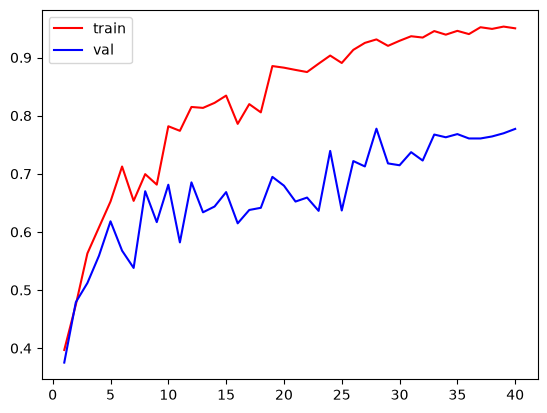

In [29]:
cnn_model_1D = MFCCNet1D(n_mfcc, n_classes)
epochs = 40
model_1D, train_uar, val_uar = train(
            cnn_model_1D, 
            make_loader(Xtr, ytr, True),
            make_loader(Xva, yva, False),
            epochs=epochs, lr=1e-3, weight_decay=2e-4
        )
fig = plt.figure()
plt.plot(range(1, epochs+1),train_uar, color="r", label="train")
plt.plot(range(1, epochs+1),val_uar, color="b", label="val")
plt.legend()
# Test set is touched exactly once, after model selection on validation.
yt, pt = predict(model_1D, make_loader(Xte, yte, False))
print(f"\nTEST accuracy {accuracy_score(yt, pt):.3f} | "
    f"UAR {balanced_accuracy_score(yt, pt):.3f}")
labels = np.arange(n_classes)
print(classification_report(yt, pt, labels=labels, target_names=le.classes_, zero_division=0))
print("Confusion matrix (rows = true, cols = predicted):")
print(pd.DataFrame(confusion_matrix(yt, pt, labels=labels), index=le.classes_, columns=le.classes_))

train UAR 0.308 | val UAR 0.250
epoch   1 | loss 1.930 | val acc 0.144 | val UAR 0.250
train UAR 0.426 | val UAR 0.221
epoch   2 | loss 1.845 | val acc 0.183 | val UAR 0.221
train UAR 0.467 | val UAR 0.281
train UAR 0.374 | val UAR 0.402
epoch   4 | loss 1.735 | val acc 0.462 | val UAR 0.402
train UAR 0.480 | val UAR 0.398
train UAR 0.380 | val UAR 0.368
epoch   6 | loss 1.621 | val acc 0.375 | val UAR 0.368
train UAR 0.464 | val UAR 0.342
train UAR 0.510 | val UAR 0.391
epoch   8 | loss 1.579 | val acc 0.433 | val UAR 0.391
train UAR 0.432 | val UAR 0.501
train UAR 0.552 | val UAR 0.394
epoch  10 | loss 1.547 | val acc 0.423 | val UAR 0.394
train UAR 0.571 | val UAR 0.290
train UAR 0.315 | val UAR 0.319
epoch  12 | loss 1.513 | val acc 0.404 | val UAR 0.319
train UAR 0.555 | val UAR 0.384
train UAR 0.398 | val UAR 0.354
epoch  14 | loss 1.439 | val acc 0.337 | val UAR 0.354
train UAR 0.617 | val UAR 0.591
train UAR 0.483 | val UAR 0.244
epoch  16 | loss 1.426 | val acc 0.212 | val UAR

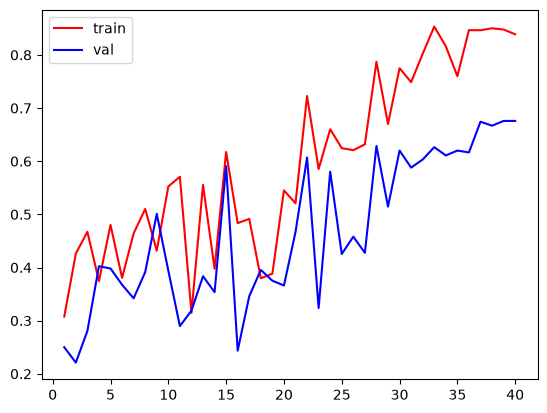

In [30]:
cnn_model_2D = MFCCNet2D(n_classes)
epochs=40
model_2D, train_uar, val_uar = train(
            cnn_model_2D, 
            make_loader(Xtr, ytr, True),
            make_loader(Xva, yva, False),
            epochs=epochs, lr=1e-3,weight_decay=6e-4
        )
fig = plt.figure()
plt.plot(range(1, epochs+1),train_uar, color="r", label="train")
plt.plot(range(1, epochs+1),val_uar, color="b", label="val")
plt.legend()
# Test set is touched exactly once, after model selection on validation.
yt, pt = predict(model_2D, make_loader(Xte, yte, False))
print(f"\nTEST accuracy {accuracy_score(yt, pt):.3f} | "
    f"UAR {balanced_accuracy_score(yt, pt):.3f}")
labels = np.arange(n_classes)
print(classification_report(yt, pt, labels=labels, target_names=le.classes_, zero_division=0))
print("Confusion matrix (rows = true, cols = predicted):")
print(pd.DataFrame(confusion_matrix(yt, pt, labels=labels), index=le.classes_, columns=le.classes_))